In [ ]:
import anndata as ad

st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/GSM9509158_breast_breast_B15_B15_rctd_annotated_dropout_1pct.h5ad')



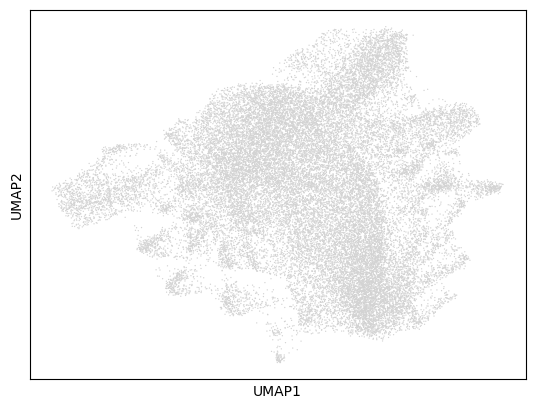

In [12]:
import scanpy as sc
adata = st_data.copy()

# Assume 'adata' is your AnnData object with a raw count matrix in adata.X
# 1. Normalize total counts per cell (default target sum = 10,000)
sc.pp.normalize_total(adata, target_sum=1e4)

# 2. Log-transform the data
sc.pp.log1p(adata)

# 3. Identify highly variable genes
# sc.pp.highly_variable_genes(adata, min_mean=0.012, max_mean=3, min_disp=0.5)
# adata = adata[:, adata.var.highly_variable]

# 4. Scale data to unit variance and zero mean
sc.pp.scale(adata, max_value=10)

# 5. Run Principal Component Analysis (PCA)
sc.tl.pca(adata, svd_solver="arpack",n_comps=50)

# 6. Compute the neighborhood graph
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=40)

# 7. Run UMAP
sc.tl.umap(adata)

# Plot the UMAP result
sc.pl.umap(adata)


In [19]:
adata[~adata.obs['rctd_spot_class'].isin(['singlet','doublet_certain'])]

View of AnnData object with n_obs × n_vars = 705 × 277
    obs: 'cell_id', 'cells_parquet_matched', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'sample_id', 'gsm_accession', 'source_h5', 'source_cells_parquet', 'xenium_n_umi', 'rctd_input_pass', 'rctd_spot_class', 'rctd_first_type', 'rctd_second_type', 'rctd_first_class', 'rctd_second_class', 'rctd_first_assignment_class_only', 'rctd_second_assignment_class_only', 'rctd_min_score', 'rctd_singlet_score', 'rctd_secondary_removed_for_singlet', 'rctd_first_weight', 'rctd_second_weight', 'batch', 'harmony_cell_type', 'split_trial_0_first_type', 'split_trial_0_n_cell_types', 'split_trial_0_primary_cell_type', 'split_trial_0_purification_status', 'split_trial_0_w1_primary', 'split_trial_1_first_type', 'split_trial_1_n_cell_types', 'split_trial_1_primary_cell_type', 'split_trial_1_puri

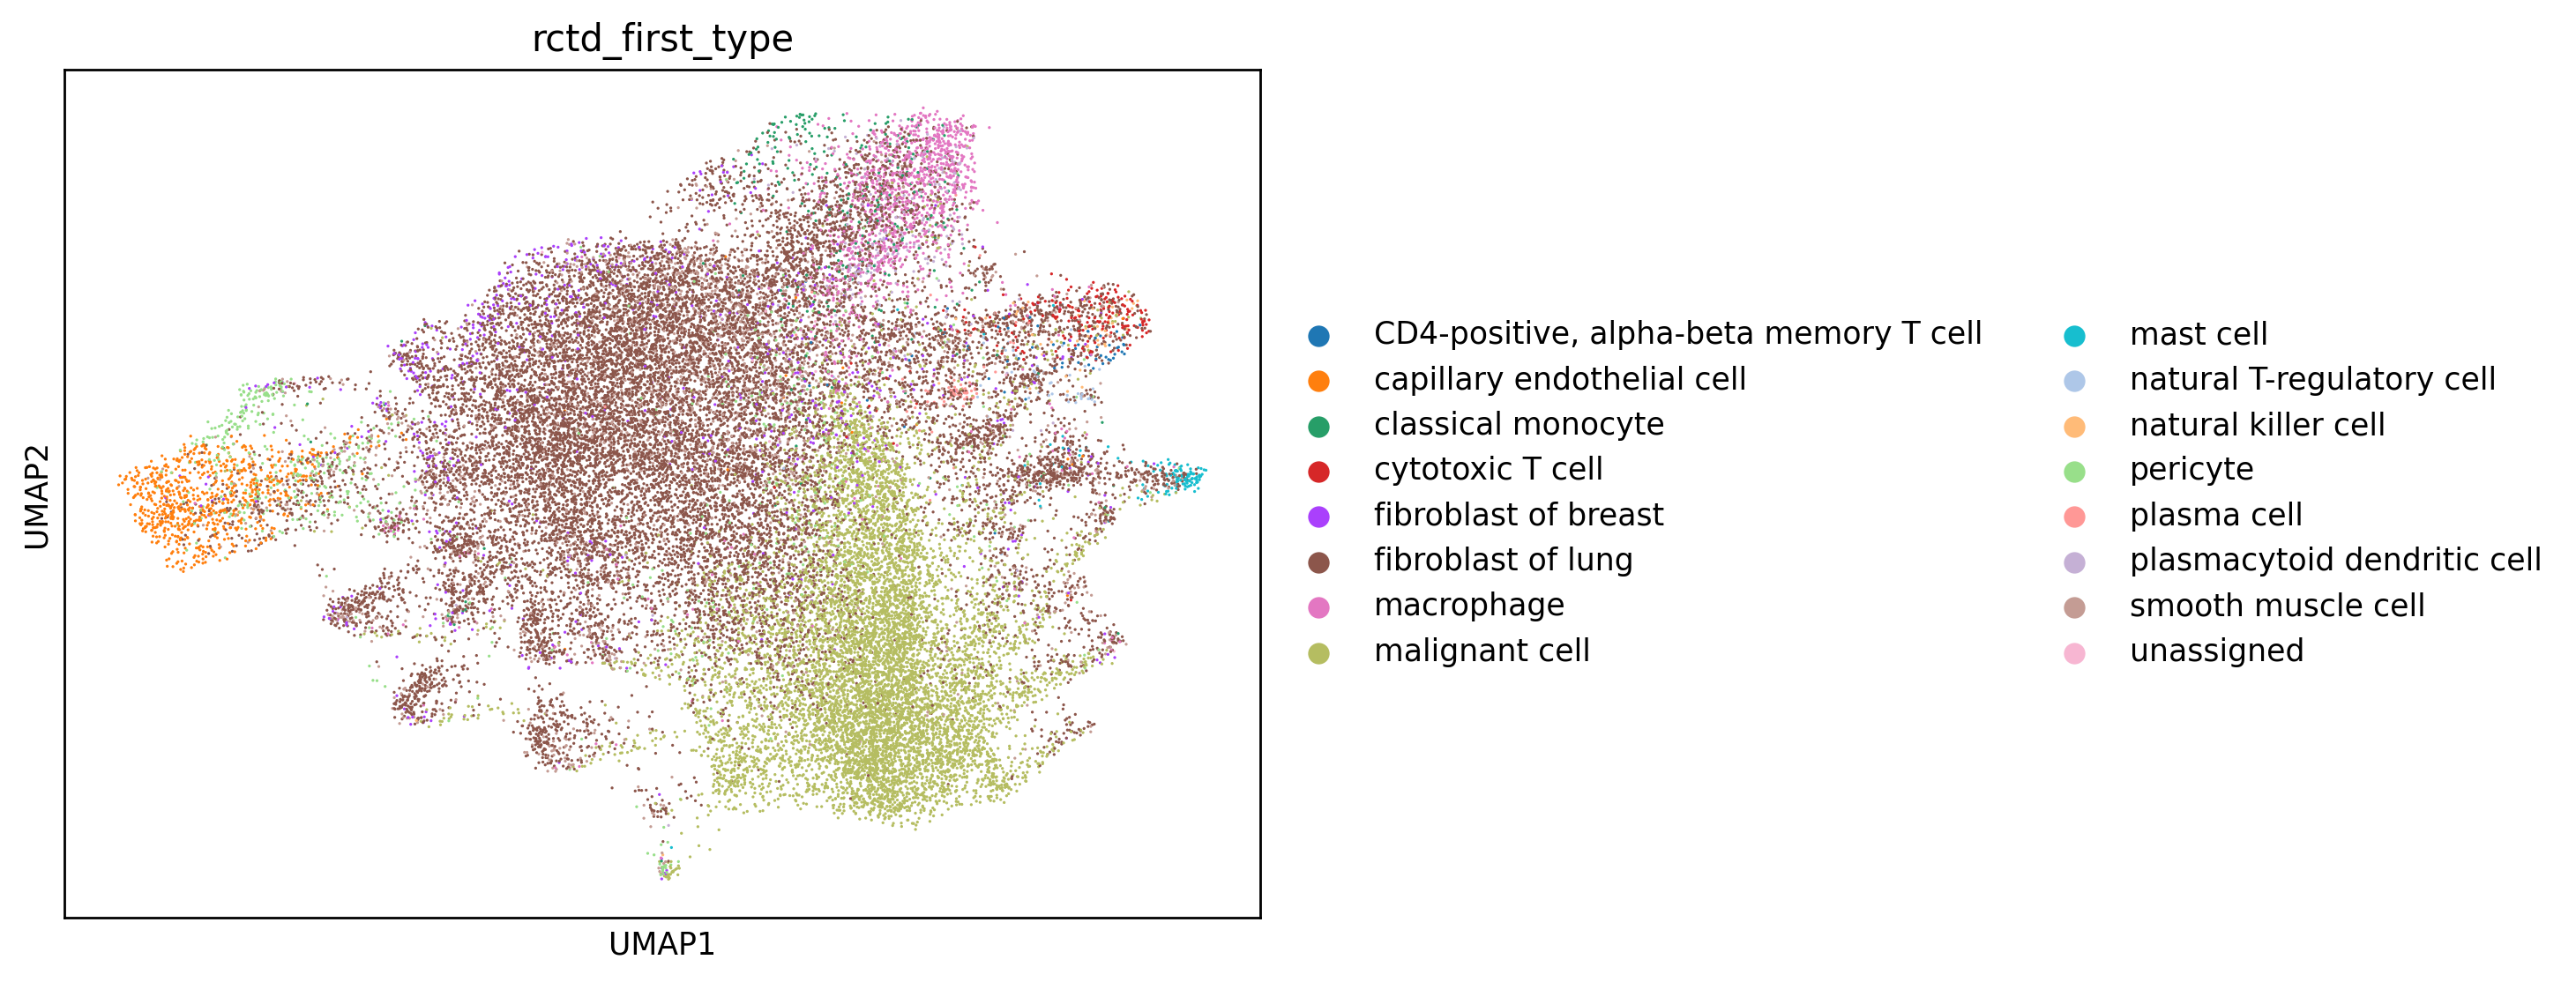

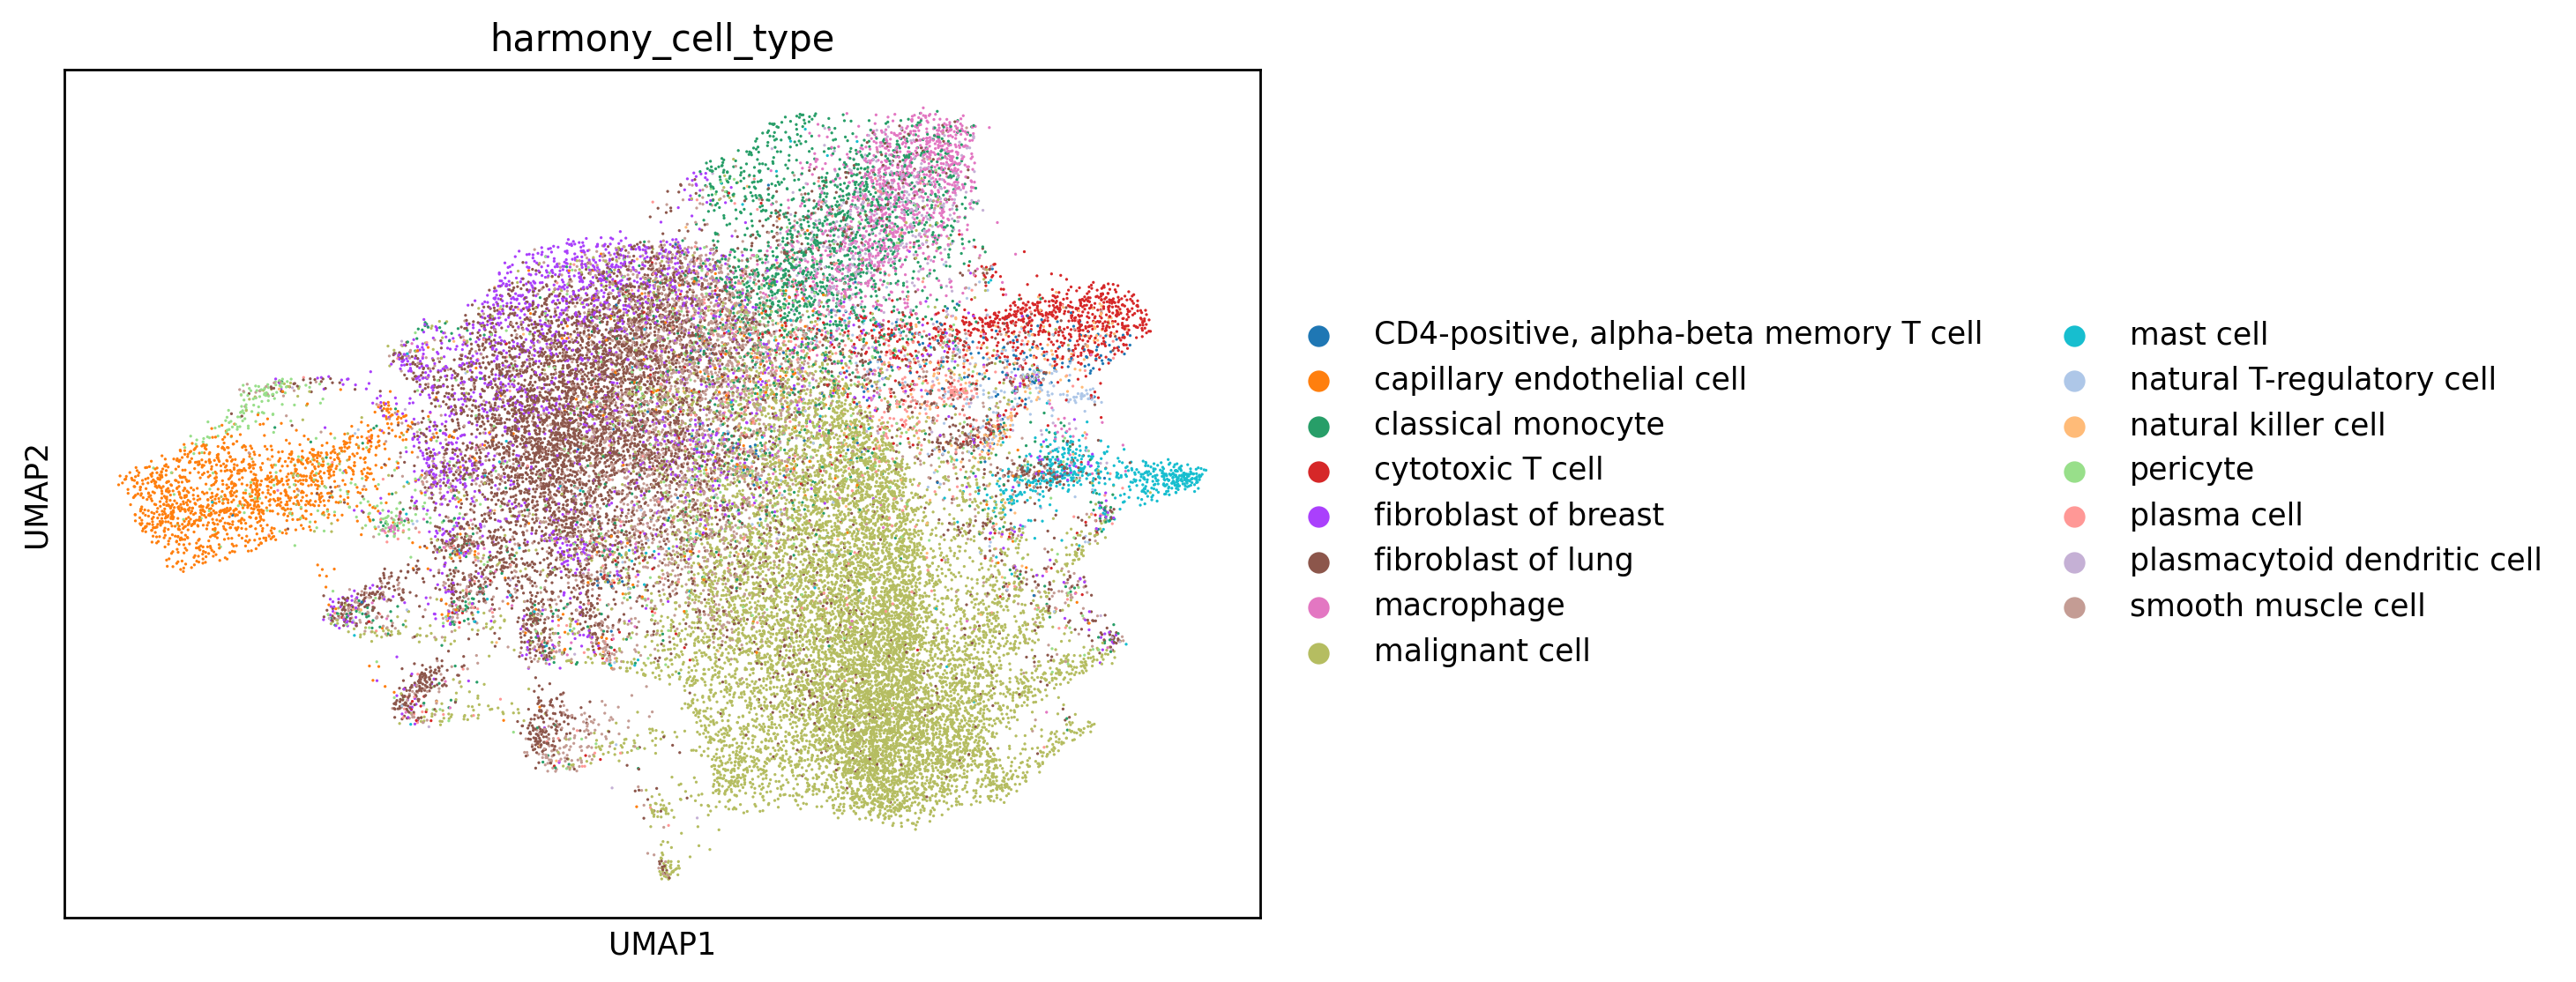

In [21]:
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize=(7,5),dpi=250)
sc.pl.umap(adata,color='rctd_first_type',ax=ax)
fig,ax = plt.subplots(figsize=(7,5),dpi=250)
sc.pl.umap(adata,color='harmony_cell_type',ax=ax)